In [1]:
#Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gurobipy as gp
from gurobipy import GRB
from portfolio_utils import (
    Portfolio, 
    read_portfolio, 
    rebalance_to_weights,
    estimate_expected_return,
    solve_lp,
    run_lp_strategy,
    estimate_covariance,
    solve_qp,
    run_qp_strategy,
    solve_ilp,
    run_ilp_strategy,
    solve_milp,
    run_milp_strategy,
    solve_miqp,
    run_miqp_strategy,
    trade_to_target_shares,
    run_hw4_buy_hold,
    run_hw4_mean_reversion,
    run_hw4_fixed_weight,
    run_hw4_investor_view
)

In [2]:
#Setup
#Load HW4 files
prices = pd.read_csv("stock_prices_hw4.csv")
initial_portfolio = pd.read_csv(
    "portfolio.txt",
    sep=r"\s+",
    header=None,
    names = ["Ticker", "Shares", "InitialPrice"]

)

#initial portfolio setup
initial_shares = dict(
    zip(
        initial_portfolio["Ticker"],
        initial_portfolio["Shares"]
    )
)

initial_prices = dict(
    zip(
        initial_portfolio["Ticker"],
        initial_portfolio["InitialPrice"]
    )
)

initial_cash = 100000.0
tickers = ["NVDA", "AAPL", "GOOG"]
t = 100

# Part A: Revisiting the Linear Program with Gurobi

In [3]:
lp_results = run_lp_strategy(
    prices,
    initial_shares,
    initial_cash,
    tickers
)

print("Buy transactions:", lp_results["buy_count"])
print("Sell transactions:", lp_results["sell_count"])
print("Dollar traded:", lp_results["dollar_traded"])
display(pd.DataFrame(lp_results["stock_weights"]))
display(pd.DataFrame(lp_results["cash_weights"]))

Set parameter Username
Set parameter LicenseID to value 2870532
Academic license - for non-commercial use only - expires 2027-10-01
Buy transactions: 14
Sell transactions: 11
Dollar traded: 1370899.1195962634


,Time,NVDA,AAPL,GOOG
0,100,0.00,0.40,0.6
1,200,0.55,0.45,0.0
2,300,0.00,0.00,0.0
3,400,0.25,0.15,0.6
4,500,0.40,0.60,0.0
5,600,0.00,0.60,0.0
6,700,0.00,0.40,0.6
7,800,0.55,0.45,0.0
8,900,0.40,0.60,0.0
9,1000,0.55,0.45,0.0


,Time,Cash
0,100,0.0
1,200,0.0
2,300,1.0
3,400,0.0
4,500,0.0
5,600,0.4
6,700,0.0
7,800,0.0
8,900,0.0
9,1000,0.0


In [4]:
#Verify homework 5 Gurobi LP against homework 4 optimization strategy

#Load Homework 4 portfolio values
hw4_results = pd.read_csv("portfolio_values.csv")

#Extract portfolio values
hw4_optimization = hw4_results["Optimization_Based"].to_numpy()
hw5_lp = np.array(lp_results["portfolio_values"])

#Round Homework 5 values to match HW4 CSV precision
hw5_lp_rounded = np.round(hw5_lp)

#Compute differences after matching precision
absolute_difference = np.abs(
    hw4_optimization - hw5_lp_rounded
)

print("HW4 observations:", len(hw4_optimization))
print("HW5 observations:", len(hw5_lp))

print(
    "\nMaximum absolute difference after rounding:",
    absolute_difference.max()
)

print(
    "Solutions agree:",
    np.allclose(
        hw4_optimization,
        hw5_lp_rounded
    )
)

#Compare values at the rebalancing dates
comparison = pd.DataFrame({
    "Time": hw4_results["Time"],
    "HW4 Optimization": hw4_optimization,
    "HW5 Gurobi LP": hw5_lp,
    "HW5 Rounded": hw5_lp_rounded,
    "Absolute Difference": absolute_difference
})

rebalance_comparison = comparison[
    comparison["Time"] % 100 == 0
]

rebalance_comparison

HW4 observations: 1000
HW5 observations: 1000

Maximum absolute difference after rounding: 0.0
Solutions agree: True


,Time,HW4 Optimization,HW5 Gurobi LP,HW5 Rounded,Absolute Difference
99,100,167222,167221.966565,167222.0,0.0
199,200,190378,190378.194797,190378.0,0.0
299,300,165546,165545.594437,165546.0,0.0
399,400,165546,165545.594437,165546.0,0.0
499,500,196732,196731.979846,196732.0,0.0
599,600,180233,180232.995758,180233.0,0.0
699,700,181419,181418.735565,181419.0,0.0
799,800,176476,176476.266049,176476.0,0.0
899,900,192020,192020.054719,192020.0,0.0
999,1000,208928,208928.206158,208928.0,0.0


# Part B: Quadratic Programming and Portfolio Risk

In [5]:
#Run the QP strategy
qp_results = run_qp_strategy(prices, initial_shares, initial_cash,tickers)

print("QP Strategy Results")
print("-------------------")
print("Buy transactions:", qp_results["buy_count"])
print("Sell transactions:", qp_results["sell_count"])
print("Dollar traded:", f"${qp_results['dollar_traded']:,.2f}")
print("\nOptimal stock weights:")
display(pd.DataFrame(qp_results["stock_weights"]))
print("Cash weights:")
display(pd.DataFrame(qp_results["cash_weights"]))
print("Expected portfolio returns:")
display(pd.DataFrame(qp_results["expected_returns"]))
print("Estimated portfolio variances:")
display(pd.DataFrame(qp_results["portfolio_variances"]))

QP Strategy Results
-------------------
Buy transactions: 14
Sell transactions: 11
Dollar traded: $1,370,899.12

Optimal stock weights:


,Time,NVDA,AAPL,GOOG
0,100,0.00,0.40,0.6
1,200,0.55,0.45,0.0
2,300,0.00,0.00,0.0
3,400,0.25,0.15,0.6
4,500,0.40,0.60,0.0
5,600,0.00,0.60,0.0
6,700,0.00,0.40,0.6
7,800,0.55,0.45,0.0
8,900,0.40,0.60,0.0
9,1000,0.55,0.45,0.0


Cash weights:


,Time,Cash
0,100,0.000000e+00
1,200,0.000000e+00
2,300,1.000000e+00
3,400,4.956431e-08
4,500,0.000000e+00
5,600,4.000000e-01
6,700,0.000000e+00
7,800,0.000000e+00
8,900,0.000000e+00
9,1000,0.000000e+00


Expected portfolio returns:


,Time,Expected Return
0,100,0.086376
1,200,0.241855
2,300,0.000000
3,400,0.087453
4,500,0.422197
5,600,0.093750
6,700,0.028241
7,800,0.060263
8,900,0.095074
9,1000,0.165656


Estimated portfolio variances:


,Time,Variance
0,100,0.000119
1,200,0.000317
2,300,0.000000
3,400,0.000207
4,500,0.000242
5,600,0.000074
6,700,0.000190
7,800,0.000264
8,900,0.000181
9,1000,0.000279


# Part C: Integer Programming and Asset Selection

In [6]:
# Run the ILP strategy
ilp_results = run_ilp_strategy(prices, initial_shares, initial_cash, tickers)

print("ILP Strategy Results")
print("--------------------")
print("Buy transactions:", ilp_results["buy_count"])
print("Sell transactions:", ilp_results["sell_count"])
print("Dollar traded:", f"${ilp_results['dollar_traded']:,.2f}")
print("\nSelected assets:")
display(pd.DataFrame(ilp_results["selected_assets"]))
print("Optimal stock weights:")
display(pd.DataFrame(ilp_results["stock_weights"]))
print("Cash weights:")
display(pd.DataFrame(ilp_results["cash_weights"]))

ilp_values = ilp_results["portfolio_values"]
print("Number of portfolio values:", len(ilp_values))
print("Final ILP portfolio value:", ilp_values[-1])
print("Maximum ILP portfolio value:", max(ilp_values))
print("Minimum ILP portfolio value:", min(ilp_values))

ILP Strategy Results
--------------------
Buy transactions: 9
Sell transactions: 15
Dollar traded: $950,343.96

Selected assets:


,Time,Selected Assets
0,100,"AAPL, GOOG"
1,200,"NVDA, AAPL"
2,300,
3,400,"NVDA, GOOG"
4,500,"NVDA, AAPL"
5,600,AAPL
6,700,"AAPL, GOOG"
7,800,NVDA
8,900,"NVDA, AAPL"
9,1000,NVDA


Optimal stock weights:


,Time,NVDA,AAPL,GOOG
0,100,0.000000,0.333333,0.333333
1,200,0.333333,0.333333,0.000000
2,300,0.000000,0.000000,0.000000
3,400,0.333333,0.000000,0.333333
4,500,0.333333,0.333333,0.000000
5,600,0.000000,0.333333,0.000000
6,700,0.000000,0.333333,0.333333
7,800,0.333333,0.000000,0.000000
8,900,0.333333,0.333333,0.000000
9,1000,0.333333,0.000000,0.000000


Cash weights:


,Time,Cash
0,100,0.333333
1,200,0.333333
2,300,1.000000
3,400,0.333333
4,500,0.333333
5,600,0.666667
6,700,0.333333
7,800,0.666667
8,900,0.333333
9,1000,0.666667


Number of portfolio values: 1000
Final ILP portfolio value: 190452.09373684452
Maximum ILP portfolio value: 213096.86980101603
Minimum ILP portfolio value: 164589.48073537563


# Part D: Mixed-Integer Linear Programming

In [7]:
#Run the MILP strategy
milp_results = run_milp_strategy(
    prices,
    initial_shares,
    initial_cash,
    tickers
)
print("MILP Strategy Results")
print("---------------------")
print("Buy transactions:", milp_results["buy_count"])
print("Sell transactions:", milp_results["sell_count"])
print("Dollar traded:", f"${milp_results['dollar_traded']:,.2f}")
print("\nSelected assets:")
display(pd.DataFrame(milp_results["selected_assets"]))
print("Optimal stock weights:")
display(pd.DataFrame(milp_results["stock_weights"]))
print("Cash weights:")
display(pd.DataFrame(milp_results["cash_weights"]))

milp_values = milp_results["portfolio_values"]

print("Number of portfolio values:", len(milp_values))
print("Final MILP portfolio value:", milp_values[-1])
print("Maximum MILP portfolio value:", max(milp_values))
print("Minimum MILP portfolio value:", min(milp_values))

MILP Strategy Results
---------------------
Buy transactions: 13
Sell transactions: 11
Dollar traded: $1,319,984.21

Selected assets:


,Time,Selected Assets
0,100,"AAPL, GOOG"
1,200,"NVDA, AAPL"
2,300,
3,400,"NVDA, GOOG"
4,500,"NVDA, AAPL"
5,600,AAPL
6,700,"AAPL, GOOG"
7,800,"NVDA, AAPL"
8,900,"NVDA, AAPL"
9,1000,"NVDA, AAPL"


Optimal stock weights:


,Time,NVDA,AAPL,GOOG
0,100,0.00,0.40,0.6
1,200,0.55,0.45,0.0
2,300,0.00,0.00,0.0
3,400,0.10,0.00,0.6
4,500,0.40,0.60,0.0
5,600,0.00,0.60,0.0
6,700,0.00,0.40,0.6
7,800,0.55,0.45,0.0
8,900,0.40,0.60,0.0
9,1000,0.55,0.45,0.0


Cash weights:


,Time,Cash
0,100,0.0
1,200,0.0
2,300,1.0
3,400,0.3
4,500,0.0
5,600,0.4
6,700,0.0
7,800,0.0
8,900,0.0
9,1000,0.0


Number of portfolio values: 1000
Final MILP portfolio value: 187226.8911089434
Maximum MILP portfolio value: 217524.36063062557
Minimum MILP portfolio value: 153687.05707283743


# Part E: Mixed-Integer Quadratic Programming

In [8]:
#Run the MIQP strategy
miqp_results = run_miqp_strategy(
    prices,
    initial_shares,
    initial_cash,
    tickers
)
print("MIQP Strategy Results")
print("---------------------")
print("Buy transactions:", miqp_results["buy_count"])
print("Sell transactions:", miqp_results["sell_count"])
print("Dollar traded:", f"${miqp_results['dollar_traded']:,.2f}")
print("\nSelected assets:")
display(pd.DataFrame(miqp_results["selected_assets"]))
print("Optimal stock weights:")
display(pd.DataFrame(miqp_results["stock_weights"]))
print("Cash weights:")
display(pd.DataFrame(miqp_results["cash_weights"]))
print("Expected portfolio returns:")
display(pd.DataFrame(miqp_results["expected_returns"]))
print("Estimated portfolio variances:")
display(pd.DataFrame(miqp_results["portfolio_variances"]))

miqp_values = miqp_results["portfolio_values"]

print("Number of portfolio values:", len(miqp_values))
print("Final MIQP portfolio value:", miqp_values[-1])
print("Maximum MIQP portfolio value:", max(miqp_values))
print("Minimum MIQP portfolio value:", min(miqp_values))

MIQP Strategy Results
---------------------
Buy transactions: 13
Sell transactions: 11
Dollar traded: $1,319,984.21

Selected assets:


,Time,Selected Assets
0,100,"AAPL, GOOG"
1,200,"NVDA, AAPL"
2,300,
3,400,"NVDA, GOOG"
4,500,"NVDA, AAPL"
5,600,AAPL
6,700,"AAPL, GOOG"
7,800,"NVDA, AAPL"
8,900,"NVDA, AAPL"
9,1000,"NVDA, AAPL"


Optimal stock weights:


,Time,NVDA,AAPL,GOOG
0,100,0.00,0.40,0.6
1,200,0.55,0.45,0.0
2,300,0.00,0.00,0.0
3,400,0.10,0.00,0.6
4,500,0.40,0.60,0.0
5,600,0.00,0.60,0.0
6,700,0.00,0.40,0.6
7,800,0.55,0.45,0.0
8,900,0.40,0.60,0.0
9,1000,0.55,0.45,0.0


Cash weights:


...

Expected portfolio returns:


,Time,Expected Return
0,100,0.086376
1,200,0.241855
2,300,0.000000
3,400,0.080971
4,500,0.422197
5,600,0.093750
6,700,0.028241
7,800,0.060263
8,900,0.095074
9,1000,0.165656


Estimated portfolio variances:


,Time,Variance
0,100,0.000119
1,200,0.000317
2,300,0.000000
3,400,0.000159
4,500,0.000242
5,600,0.000074
6,700,0.000190
7,800,0.000264
8,900,0.000181
9,1000,0.000279


Number of portfolio values: 1000
Final MIQP portfolio value: 187226.8911089434
Maximum MIQP portfolio value: 217524.36063062557
Minimum MIQP portfolio value: 153687.05707283743


# Part F: Model and Strategy Comparison

In [9]:
# Combine portfolio values from all nine strategies
strategy_values = pd.DataFrame({
    "Time": hw4_results["Time"],

    # Homework 4 strategies
    "BH": hw4_results["Buy_and_Hold"],
    "HW1": hw4_results["Mean_Reversion"],
    "RB": hw4_results["Fixed_Weight"],
    "IV": hw4_results["Investor_View"],

    # Homework 5 optimization models
    "LP": lp_results["portfolio_values"],
    "QP": qp_results["portfolio_values"],
    "ILP": ilp_results["portfolio_values"],
    "MILP": milp_results["portfolio_values"],
    "MIQP": miqp_results["portfolio_values"]
})

strategy_values.head()

,Time,BH,HW1,RB,IV,LP,QP,ILP,MILP,MIQP
0,1,165518,165518,165518,165518,165517.501723,165517.501723,165517.501723,165517.501723,165517.501723
1,2,165093,165093,165093,165093,165092.683853,165092.683853,165092.683853,165092.683853,165092.683853
2,3,165633,165633,165633,165633,165632.827607,165632.827607,165632.827607,165632.827607,165632.827607
3,4,166031,166031,166031,166031,166030.955570,166030.955570,166030.955570,166030.955570,166030.955570
4,5,165903,165903,165903,165903,165902.618638,165902.618638,165902.618638,165902.618638,165902.618638


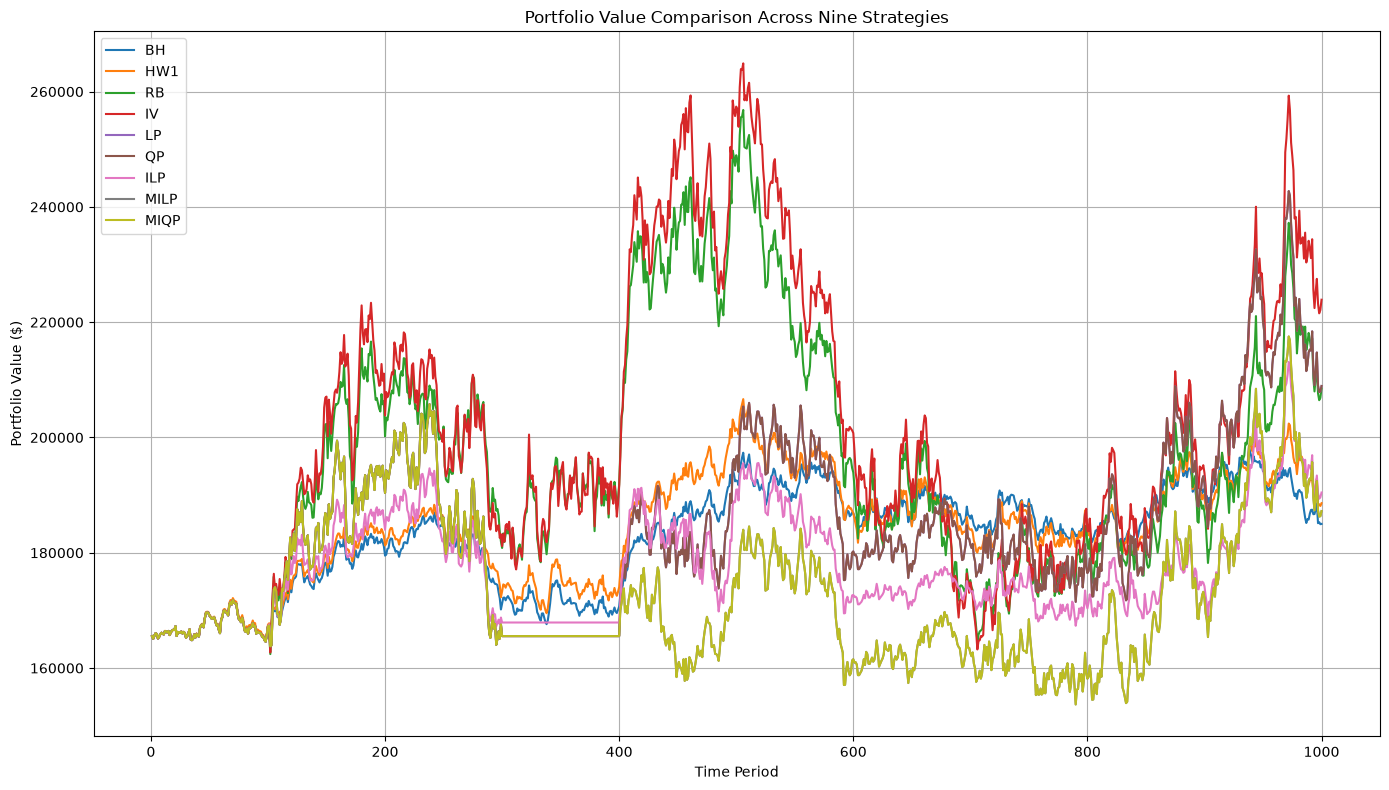

In [10]:
#Plot all nine portfolio strategies

plt.figure(figsize=(14, 8))

strategies = [
    "BH",
    "HW1",
    "RB",
    "IV",
    "LP",
    "QP",
    "ILP",
    "MILP",
    "MIQP"
]

for strategy in strategies:
    plt.plot(
        strategy_values["Time"],
        strategy_values[strategy],
        label=strategy
    )

plt.title("Portfolio Value Comparison Across Nine Strategies")
plt.xlabel("Time Period")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "part_f_strategy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
#Create summary of portfolio values
summary_rows = []

for strategy in strategies:

    values = strategy_values[strategy]

    summary_rows.append({
        "Strategy": strategy,
        "Final Value": values.iloc[-1],
        "Maximum Value": values.max(),
        "Minimum Value": values.min()
    })

summary_table = pd.DataFrame(summary_rows)

summary_table

,Strategy,Final Value,Maximum Value,Minimum Value
0,BH,185004.000000,198489.000000,164589.000000
1,HW1,188600.000000,206652.000000,164710.000000
2,RB,208501.000000,256814.000000,162424.000000
3,IV,223898.000000,264896.000000,162709.000000
4,LP,208928.206158,242738.940577,163786.460737
5,QP,208928.206158,242738.940577,163786.460737
6,ILP,190452.093737,213096.869801,164589.480735
7,MILP,187226.891109,217524.360631,153687.057073
8,MIQP,187226.891109,217524.360631,153687.057073


In [17]:
#Trade statistics for Homework 5 strategies
new_trade_stats = {
    "LP": {
        "Buy Transactions": lp_results["buy_count"],
        "Sell Transactions": lp_results["sell_count"],
        "Dollar Traded": lp_results["dollar_traded"]
    },

    "QP": {
        "Buy Transactions": qp_results["buy_count"],
        "Sell Transactions": qp_results["sell_count"],
        "Dollar Traded": qp_results["dollar_traded"]
    },

    "ILP": {
        "Buy Transactions": ilp_results["buy_count"],
        "Sell Transactions": ilp_results["sell_count"],
        "Dollar Traded": ilp_results["dollar_traded"]
    },

    "MILP": {
        "Buy Transactions": milp_results["buy_count"],
        "Sell Transactions": milp_results["sell_count"],
        "Dollar Traded": milp_results["dollar_traded"]
    },

    "MIQP": {
        "Buy Transactions": miqp_results["buy_count"],
        "Sell Transactions": miqp_results["sell_count"],
        "Dollar Traded": miqp_results["dollar_traded"]
    }
}

# Homework 4 trade statistics
# Fill these using the statistics from the same HW4 simulation run

old_trade_stats = {
    "BH": {
        "Buy Transactions": 0,
        "Sell Transactions": 0,
        "Dollar Traded": 0.0
    },

    "HW1": {
        "Buy Transactions": 112,
        "Sell Transactions": 72,
        "Dollar Traded": 283583.71
    },

    "RB": {
        "Buy Transactions": 16,
        "Sell Transactions": 14,
        "Dollar Traded": 320622.11
    },

    "IV": {
        "Buy Transactions": 17,
        "Sell Transactions": 13,
        "Dollar Traded": 317349.36
    }
}

In [18]:
#Combine Homework 4 and Homework 5 trade statistics
trade_stats = {
    **old_trade_stats,
    **new_trade_stats
}

#Portfolio value results for all strategies
value_results = {
    "BH": bh_results["portfolio_values"],
    "HW1": mr_results["portfolio_values"],
    "RB": rb_results["portfolio_values"],
    "IV": iv_results["portfolio_values"],
    "LP": lp_results["portfolio_values"],
    "QP": qp_results["portfolio_values"],
    "ILP": ilp_results["portfolio_values"],
    "MILP": milp_results["portfolio_values"],
    "MIQP": miqp_results["portfolio_values"]
}

summary_rows = []

for strategy, values in value_results.items():

    summary_rows.append({
        "Strategy": strategy,
        "Final Value": values[-1],
        "Maximum Value": max(values),
        "Minimum Value": min(values),
        "Buys": trade_stats[strategy]["Buy Transactions"],
        "Sells": trade_stats[strategy]["Sell Transactions"],
        "Dollar Traded": trade_stats[strategy]["Dollar Traded"]
    })

summary_table = pd.DataFrame(summary_rows)

display(
    summary_table.style.format({
        "Final Value": "${:,.2f}",
        "Maximum Value": "${:,.2f}",
        "Minimum Value": "${:,.2f}",
        "Buys": "{:.0f}",
        "Sells": "{:.0f}",
        "Dollar Traded": "${:,.2f}"
    })
)

,Strategy,Final Value,Maximum Value,Minimum Value,Buys,Sells,Dollar Traded
0,BH,"$185,003.69","$198,488.74","$164,589.48",0,0,$0.00
1,HW1,"$188,600.21","$206,651.59","$164,709.71",112,72,"$283,583.71"
2,RB,"$208,501.17","$256,813.98","$162,423.53",16,14,"$320,622.11"
3,IV,"$223,898.18","$264,896.48","$162,709.40",17,13,"$317,349.36"
4,LP,"$208,928.21","$242,738.94","$163,786.46",14,11,"$1,370,899.12"
5,QP,"$208,928.21","$242,738.94","$163,786.46",14,11,"$1,370,899.12"
6,ILP,"$190,452.09","$213,096.87","$164,589.48",9,15,"$950,343.96"
7,MILP,"$187,226.89","$217,524.36","$153,687.06",13,11,"$1,319,984.21"
8,MIQP,"$187,226.89","$217,524.36","$153,687.06",13,11,"$1,319,984.21"


# Appendix
Because HW4's strategies' data was unrecovarable, we simulate the strategies using the same price path obtained for HW5's strategies to get the correct data under this specific price path.

In [13]:
#Verify that the fixed path begins with the portfolio's initial prices

for stock in tickers:
    print(
        stock,
        initial_prices[stock],
        prices.loc[0, stock]
    )

NVDA 78.54 78.54
AAPL 189.72 189.72
GOOG 173.88 173.88


In [14]:
#Rerun all four Homework 4 strategies

bh_results = run_hw4_buy_hold(
    prices,
    initial_shares,
    initial_cash,
    tickers
)

mr_results = run_hw4_mean_reversion(
    prices,
    initial_shares,
    initial_prices,
    initial_cash,
    tickers
)

rb_results = run_hw4_fixed_weight(
    prices,
    initial_shares,
    initial_cash,
    tickers
)

iv_results = run_hw4_investor_view(
    prices,
    initial_shares,
    initial_cash,
    tickers
)

In [15]:
hw4_trade_stats = pd.DataFrame([
    {
        "Strategy": "BH",
        "Buys": bh_results["buy_count"],
        "Sells": bh_results["sell_count"],
        "Dollar Traded": bh_results["dollar_traded"]
    },
    {
        "Strategy": "HW1",
        "Buys": mr_results["buy_count"],
        "Sells": mr_results["sell_count"],
        "Dollar Traded": mr_results["dollar_traded"]
    },
    {
        "Strategy": "RB",
        "Buys": rb_results["buy_count"],
        "Sells": rb_results["sell_count"],
        "Dollar Traded": rb_results["dollar_traded"]
    },
    {
        "Strategy": "IV",
        "Buys": iv_results["buy_count"],
        "Sells": iv_results["sell_count"],
        "Dollar Traded": iv_results["dollar_traded"]
    }
])

display(
    hw4_trade_stats.style.format({
        "Dollar Traded": "${:,.2f}"
    })
)

,Strategy,Buys,Sells,Dollar Traded
0,BH,0,0,$0.00
1,HW1,112,72,"$283,583.71"
2,RB,16,14,"$320,622.11"
3,IV,17,13,"$317,349.36"
